2026.10.28 一致性修订：请 Restart Kernel & Run All。初始化会验证当前 embedding→特征→预测→概率；旧 niche 缓存不再复用，旧图输出已清空。Deployment 最佳模型用法保持不变。


# BRCA external validation — pan-cancer Hist2Pheno (UNI2 A3)

UNI2 A3 uses a 14 px crop (7 µm after rescale to 0.5 µm/px). Run `demo_uni2_A3.sh`. UNI predictions stay in `pred_pancancer_section`.


Three HE + StarDist slides under `data/Visium/BRCA` (**no cell-type GT**):

| Sample | HE | µm/px |
|--------|----|-------|
| `GSM7782699_tissue_image` | OME TIFF | ~0.548 (OME PhysicalSize) |
| `200715_BC_SA2_C_D_V19F24-113.B1-Spot000001` | pathology JPEG → Visium `V10F24-113_B1` | ~0.172 (Visium × HE÷SR) |
| `200219_BC_SA3_V19T26-031_CE_V4-Spot000001` | pathology JPEG → Visium `V19T26-031_D1` | ~0.172 (Visium × HE÷SR) |

Predictions use the pan-cancer **cross-section** checkpoint
`A3_adjacent_spatial_k8mean_gate` (L1 / L12 / L2), spatial k=8 mean with a learned gate.
Cohort helper: `code/External_val/BRCA/brca_external.py` (mixed HE suffix + per-sample mpp).
Zenodo JPEGs are ~3.333× Space Ranger fullres — do **not** use raw `65/spot_diameter` on them.

```bash
conda activate SeededNTM
bash code/External_val/BRCA/demo_uni2_A3.sh dry-run
SAMPLE=200715_BC_SA2_C_D_V19F24-113.B1-Spot000001 bash code/External_val/BRCA/demo_uni2_A3.sh all
```

Outputs: `data/Visium/BRCA/pred_uni2_A3_bestmlp_paired_v2_seed42/`.


In [1]:
import sys
from pathlib import Path

REPO = Path("/home/lingyu/ssd2/Python/Hist2Pheno")
# 2026.10.28, explicit checkout override / Farm 可设 HIST2PHENO_REPO
import os
if os.environ.get("HIST2PHENO_REPO"):
    REPO = Path(os.environ["HIST2PHENO_REPO"]).expanduser().resolve()
if not (REPO / "code").is_dir():
    REPO = Path("/nobackup2/users/lingyu/Python/Hist2Pheno")
import os
os.environ["UNI2_CKPT"] = str(REPO / "data/PanCancer/result_uni2_A3_adjacent_spatial_k8mean_gate_paired_v2_seed42/cross_dataset_cv/A3_adjacent_spatial_k8mean_gate/best_mlp_gpu.pt")
STAR_PROB_MIN = 0.0  # 2026.10.28, set above 0 to store a separate _probXX folder
import os as _prob_os
_prob_os.environ["STAR_PROB_MIN"] = "0" if float(STAR_PROB_MIN) <= 0 else f"{float(STAR_PROB_MIN):.2f}"
os.environ["UNI2_PRED_DIRNAME"] = "pred_uni2_A3_bestmlp_paired_v2_seed42"
sys.path.insert(0, str(REPO / "code"))
sys.path.insert(0, str(REPO / "code" / "External_val" / "BRCA"))

import brca_external as brca_ext
brca_ext.use_embedder("uni2")

PRED_ROOT = brca_ext.PRED_ROOT
composition_table = brca_ext.composition_table
discover_samples = brca_ext.discover_samples
geometry = brca_ext.geometry
sample_paths = brca_ext.sample_paths
ensure_l2_probs = brca_ext.ensure_l2_probs
plot_spatial = brca_ext.plot_spatial
plot_composition = brca_ext.plot_composition
plot_roi_spatial = brca_ext.plot_roi_spatial
plot_roi_composition = brca_ext.plot_roi_composition
# Re-run the plot cell after changing these. Notebook display uses DPI; saved PNGs use SAVE_DPI.
SAVE_FIGURES = False
FIGSIZE = (20.4, 7.8)
DPI = 200
SAVE_DPI = 300
HE_MAX_SIDE = 1400
MARKER_PX = 1.0

samples = discover_samples()
for sample in samples:
    g = geometry(sample)
    print(
        f"{sample}  mpp={g['mpp_um']:.4f} µm/px  "
        f"({g['mpp_source']})  "
        f"native14={g['patch_um_if_native_16px']:.2f} µm  "
        f"after rescale={g['patch_um_after_rescale']:.1f} µm  "
        f"scale={g['scale']:.4f}"
    )
    p = sample_paths(sample)
    print(f"  HE: {p['he'].name}  pred exists: {p['pred'].is_file()}")

# 2026.10.28, mandatory current-input preflight / 后续直接读 h5ad 的图表也不得绕过上游
import os as _pipeline_os
_pipeline_os.environ["STAR_PROB_MIN"] = str(globals().get("STAR_PROB_MIN", 0.0))
if "ensure_l2_probs" in globals():
    _owner = ensure_l2_probs.__self__
    _current_samples = list(samples) if "samples" in globals() else _owner.discover_samples()
    _owner.cmd_predict(_current_samples, force=False, allow_cpu=True)
elif "ue" in globals():
    ue.cmd_predict(COHORT, samples, cuda_device=_pipeline_os.environ.get("CUDA_DEVICE", "0"),
                   force=False, allow_cpu=True, embedder=EMBEDDER)
else:
    raise RuntimeError("No current prediction validator; run the setup cell first")


200219_BC_SA3_V19T26-031_CE_V4-Spot000001  mpp=0.1721 µm/px  (Visium V19T26-031_D1: (65/spot_diameter_fullres=113.3115) / HE÷SR=3.3333)  native14=2.41 µm  after rescale=7.0 µm  scale=0.3442
  HE: 200219_BC_SA3_V19T26-031_CE_V4-Spot000001.jpg  pred exists: True
200715_BC_SA2_C_D_V19F24-113.B1-Spot000001  mpp=0.1720 µm/px  (Visium V10F24-113_B1: (65/spot_diameter_fullres=113.3916) / HE÷SR=3.3333)  native14=2.41 µm  after rescale=7.0 µm  scale=0.3439
  HE: 200715_BC_SA2_C_D_V19F24-113.B1-Spot000001.jpg  pred exists: True
GSM7782699_tissue_image  mpp=0.5476 µm/px  (OME PhysicalSize)  native14=7.67 µm  after rescale=7.0 µm  scale=1.0952
  HE: GSM7782699_tissue_image.tif  pred exists: True
[h5ad] load embeddings /nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/BRCA/project_all_UNI2/200219_BC_SA3_V19T26-031_CE_V4-Spot000001/ImgEmbeddings_all_stardist/sc_pth_14_14
  Using specified coordinates: centroid_x, centroid_y
  Building KDTree for embeddings: 391,069 points
  KDTree matched 391,06

In [2]:
import pandas as pd
from IPython.display import Image, display

missing = [s for s in samples if not sample_paths(s)["pred"].is_file()]
if missing:
    raise FileNotFoundError(
        "No predictions yet for "
        + ", ".join(missing)
        + ". Run: bash code/External_val/BRCA/demo_uni2_A3.sh all"
    )

comp = composition_table(samples)

for head in ("L1", "L12", "L2"):
    sub = comp.loc[comp["head"] == head].copy()
    order = sub.groupby("class")["fraction"].max().sort_values(ascending=False).index
    wide = (
        sub.pivot_table(index="class", columns="sample", values=["fraction", "n", "mean_conf"])
        .reindex(order)
    )
    print(f"\n===== {head} =====")
    display(wide.round(3))



===== L1 =====


fraction  \
sample      200219_BC_SA3_V19T26-031_CE_V4-Spot000001   
class                                                   
Epithelial                                      0.584   
Stromal                                         0.117   
Endothelial                                     0.122   
Immune                                          0.176   
Neural                                          0.001   

                                                        \
sample      200715_BC_SA2_C_D_V19F24-113.B1-Spot000001   
class                                                    
Epithelial                                       0.924   
Stromal                                          0.013   
Endothelial                                      0.026   
Immune                                           0.036   
Neural                                           0.001   

                                                                    mean_conf  \
sample      GSM7782699_tissue_image 200219_BC_SA3_V19T26-031_CE_V4-Spot000001   
class                                                                           
Epithelial                    0.170                                     0.751   
Stromal                       0.312                                     0.469   
Endothelial                   0.300                                     0.458   
Immune                        0.136                                     0.526   
Neural                        0.082                                     0.533   

                                                        \
sample      200715_BC_SA2_C_D_V19F24-113.B1-Spot000001   
class                                                    
Epithelial                                       0.836   
Stromal                                          0.462   
Endothelial                                      0.462   
Immune                                           0.558   
Neural                                           0.619   

                                                                            n  \
sample      GSM7782699_tissue_image 200219_BC_SA3_V19T26-031_CE_V4-Spot000001   
class                                                                           
Epithelial                    0.600                                  228577.0   
Stromal                       0.569                                   45872.0   
Endothelial                   0.591                                   47521.0   
Immune                        0.599                                   68802.0   
Neural                        0.670                                     297.0   

                                                                                
sample      200715_BC_SA2_C_D_V19F24-113.B1-Spot000001 GSM7782699_tissue_image  
class                                                                           
Epithelial                                    344030.0                 47905.0  
Stromal                                         4806.0                 87595.0  
Endothelial                                     9773.0                 84362.0  
Immune                                         13417.0                 38239.0  
Neural                                           387.0                 22948.0


===== L12 =====


fraction  \
sample      200219_BC_SA3_V19T26-031_CE_V4-Spot000001   
class                                                   
Tumor                                           0.133   
Stromal                                         0.117   
Epithelial                                      0.353   
Myeloid                                         0.314   
Endothelial                                     0.020   
T_cell                                          0.062   
B_Plasma                                        0.001   
Neural                                          0.000   

                                                        \
sample      200715_BC_SA2_C_D_V19F24-113.B1-Spot000001   
class                                                    
Tumor                                            0.725   
Stromal                                          0.021   
Epithelial                                       0.176   
Myeloid                                          0.020   
Endothelial                                      0.006   
T_cell                                           0.040   
B_Plasma                                         0.013   
Neural                                           0.000   

                                                                    mean_conf  \
sample      GSM7782699_tissue_image 200219_BC_SA3_V19T26-031_CE_V4-Spot000001   
class                                                                           
Tumor                         0.175                                     0.630   
Stromal                       0.392                                     0.437   
Epithelial                    0.046                                     0.682   
Myeloid                       0.081                                     0.456   
Endothelial                   0.161                                     0.388   
T_cell                        0.112                                     0.462   
B_Plasma                      0.028                                     0.358   
Neural                        0.006                                     0.458   

                                                        \
sample      200715_BC_SA2_C_D_V19F24-113.B1-Spot000001   
class                                                    
Tumor                                            0.711   
Stromal                                          0.382   
Epithelial                                       0.586   
Myeloid                                          0.345   
Endothelial                                      0.369   
T_cell                                           0.426   
B_Plasma                                         0.418   
Neural                                           0.486   

                                                                            n  \
sample      GSM7782699_tissue_image 200219_BC_SA3_V19T26-031_CE_V4-Spot000001   
class                                                                           
Tumor                         0.597                                   51877.0   
Stromal                       0.503                                   45768.0   
Epithelial                    0.455                                  138133.0   
Myeloid                       0.393                                  122787.0   
Endothelial                   0.471                                    7850.0   
T_cell                        0.522                                   24396.0   
B_Plasma                      0.456                                     256.0   
Neural                        0.488                                       2.0   

                                                                                
sample      200715_BC_SA2_C_D_V19F24-113.B1-Spot000001 GSM7782699_tissue_image  
class                                                                           
Tumor                                         269968.0                 49103.0  
Stromal                        


===== L2 =====


fraction  \
sample            200219_BC_SA3_V19T26-031_CE_V4-Spot000001   
class                                                         
Tumor                                                 0.127   
Endothelial                                           0.056   
Macrophage                                            0.190   
Epithelial                                            0.184   
Injury_epithelial                                     0.148   
Fibroblast                                            0.045   
Myofibroblast                                         0.092   
Stromal                                               0.000   
B_cell                                                0.011   
Neutrophil                                            0.047   
Alveolar                                              0.037   
CD4_T                                                 0.034   
Neural                                                0.000   
Plasma                                                0.002   
CD8_T                                                 0.010   
Myoepithelial                                         0.001   
DCIS                                                  0.006   
Tregs                                                 0.002   
NK                                                    0.006   
DC                                                    0.002   

                                                              \
sample            200715_BC_SA2_C_D_V19F24-113.B1-Spot000001   
class                                                          
Tumor                                                  0.729   
Endothelial                                            0.017   
Macrophage                                             0.009   
Epithelial                                             0.115   
Injury_epithelial                                      0.017   
Fibroblast                                             0.004   
Myofibroblast                                          0.004   
Stromal                                                0.005   
B_cell                                                 0.020   
Neutrophil                                             0.006   
Alveolar                                               0.001   
CD4_T                                                  0.009   
Neural                                                 0.000   
Plasma                                                 0.015   
CD8_T                                                  0.012   
Myoepithelial                                          0.018   
DCIS                                                   0.016   
Tregs                                                  0.001   
NK                                                     0.001   
DC                                                     0.000   

                                           \
sample            GSM7782699_tissue_image   
class                                       
Tumor                               0.169   
Endothelial                         0.235   
Macrophage                          0.015   
Epithelial                          0.031   
Injury_epithelial                   0.003   
Fibroblast                          0.122   
Myofibroblast                       0.113   
Stromal                             0.065   
B_cell                              0.062   
Neutrophil                          0.040   
Alveolar                            0.004   
CD4_T                               0.029   
Neural                              0.032   
Plasma                              0.028   
CD8_T                               0.025   
Myoepithelial                       0.000   
DCIS                                0.005   
Tregs                               0.015   
NK                                  0.005   
DC                                  0.003   

                                                  mean_conf  \
sample            200219_BC_S

[plot] 200219_BC_SA3_V19T26-031_CE_V4-Spot000001  nuclei=391,069  neighbor=23.8px  figsize=(20.4, 14.819999999999999)  dpi=200  marker_px=1.0  rows=HE+points
[plot] 200715_BC_SA2_C_D_V19F24-113.B1-Spot000001  nuclei=372,413  neighbor=23.4px  figsize=(20.4, 14.819999999999999)  dpi=200  marker_px=1.0  rows=HE+points
[plot] GSM7782699_tissue_image  nuclei=281,049  neighbor=12.8px  figsize=(20.4, 14.819999999999999)  dpi=200  marker_px=1.0  rows=HE+points


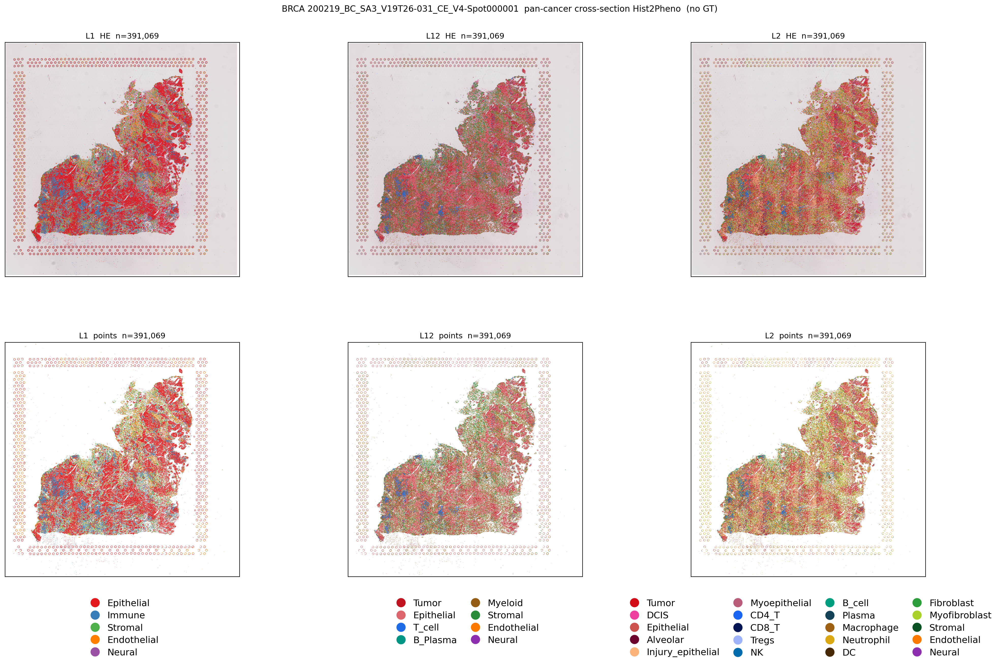

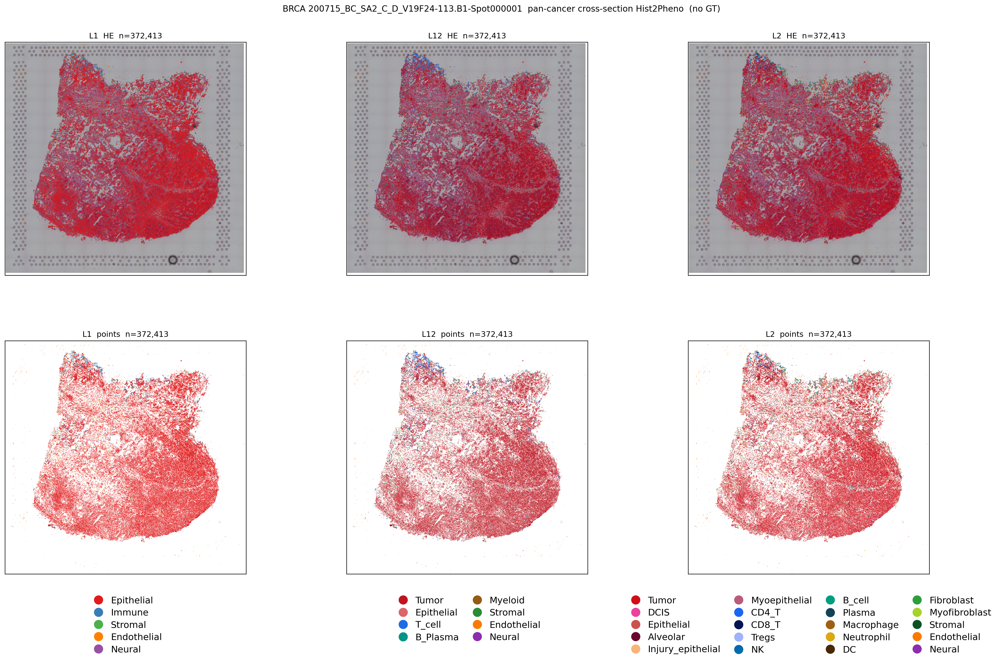

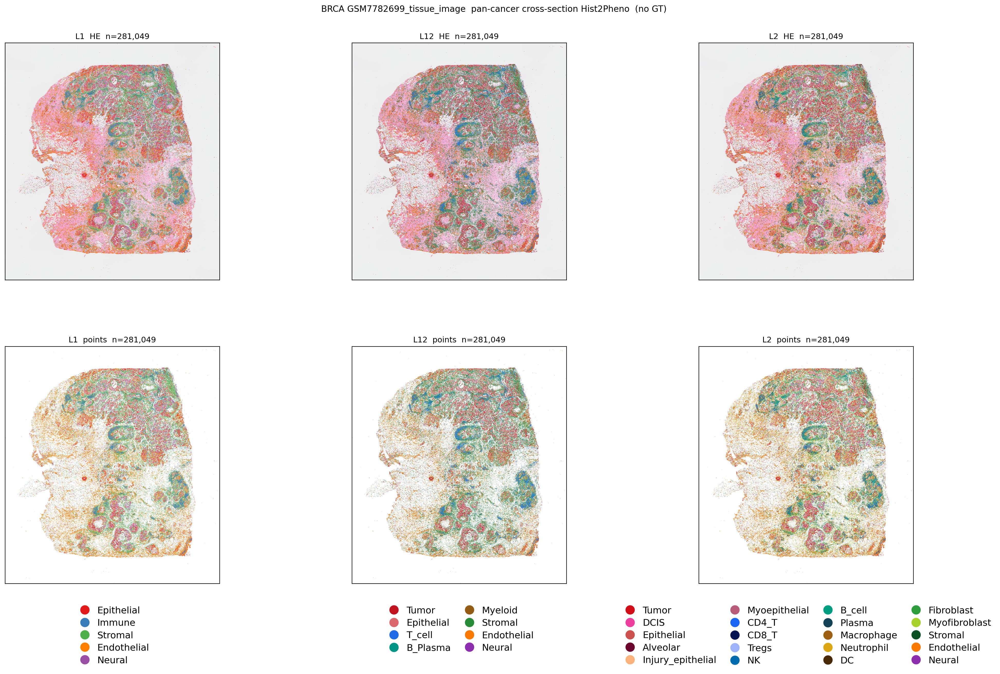

In [3]:
import matplotlib.pyplot as plt

for fig in plot_spatial(
    samples,
    figsize=FIGSIZE,
    dpi=DPI,
    he_max_side=HE_MAX_SIDE,
    marker_px=MARKER_PX,
    save=SAVE_FIGURES,
    save_dpi=SAVE_DPI,
):
    display(fig)
    plt.close(fig)


### Single section + QuPath ROI

Section: `200219_BC_SA3_V19T26-031_CE_V4-Spot000001`  
ROI: `data/Visium/BRCA/HE_images/selected_rectangle_coordinates.tsv` (native HE pixels).


[plot] 200219_BC_SA3_V19T26-031_CE_V4-Spot000001  nuclei=391,069  neighbor=23.8px  figsize=(20.4, 14.819999999999999)  dpi=200  marker_px=1.0  rows=HE+points


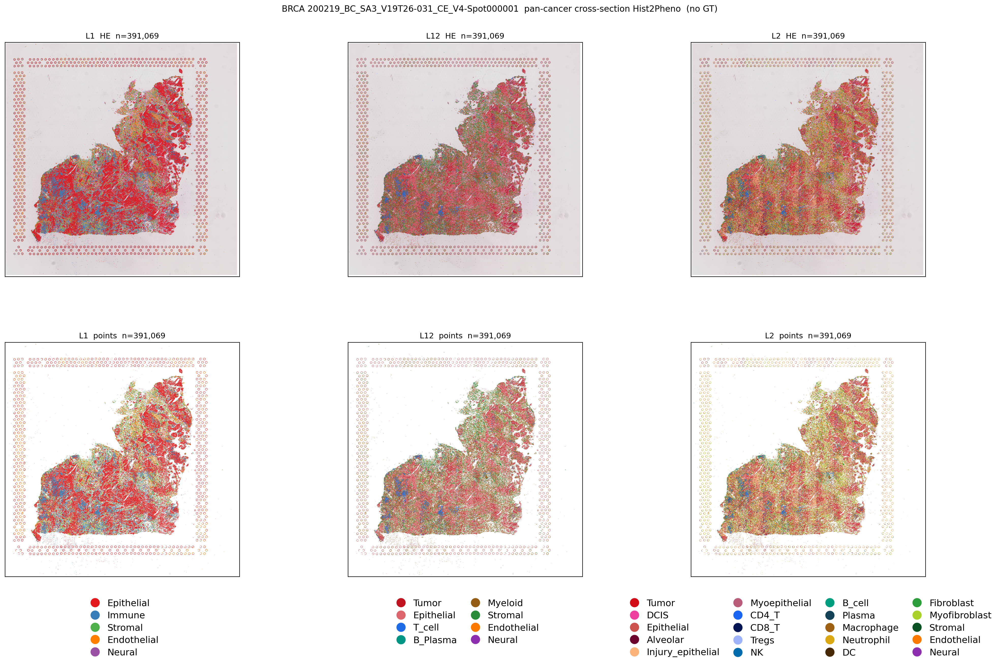

In [4]:
# One section only (full slide L1 / L12 / L2)
SAMPLE_ROI = "200219_BC_SA3_V19T26-031_CE_V4-Spot000001"
if SAMPLE_ROI not in samples:
    raise FileNotFoundError(
        f"{SAMPLE_ROI} not in discover_samples(): {samples}. "
        "Run: SAMPLE=... bash code/External_val/BRCA/demo_uni2_A3.sh all"
    )
if not sample_paths(SAMPLE_ROI)["pred"].is_file():
    raise FileNotFoundError(sample_paths(SAMPLE_ROI)["pred"])

for fig in plot_spatial(
    [SAMPLE_ROI],
    figsize=FIGSIZE,
    dpi=DPI,
    he_max_side=HE_MAX_SIDE,
    marker_px=MARKER_PX,
    save=SAVE_FIGURES,
    save_dpi=SAVE_DPI,
):
    display(fig)
    plt.close(fig)


ROI 200219_BC_SA3_V19T26-031_CE_V4-Spot000001: x=[18296,20794] y=[39862,41783]  nuclei=2,595  MARKER_PX_ROI=10.0


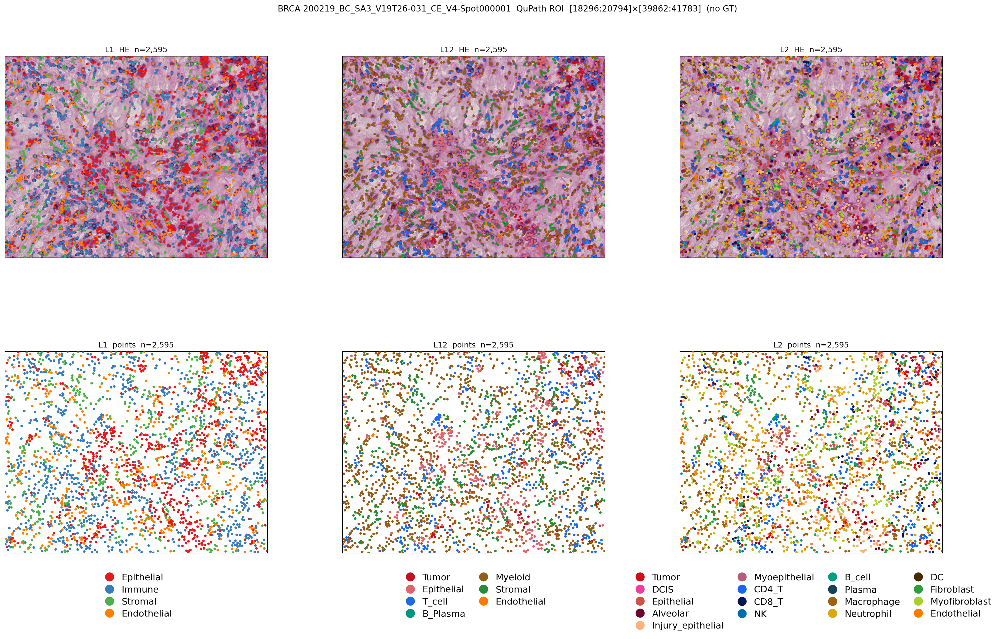

In [5]:
# ROI from QuPath rectangle → L1 / L12 / L2 on cropped HE
# Full-slide MARKER_PX (~1) is too small once the view is a ~2.5k×2k crop.
ROI_TSV = REPO / "data" / "Visium" / "BRCA" / "HE_images" / "selected_rectangle_coordinates.tsv"
MARKER_PX_ROI = max(float(MARKER_PX) * 5.0, 10.0)
fig_h = float(FIGSIZE[1]) * 1.9 if FIGSIZE[1] <= 8.5 else float(FIGSIZE[1])

fig, pred, in_roi, roi = plot_roi_spatial(
    SAMPLE_ROI,
    ROI_TSV,
    marker_px=MARKER_PX_ROI,
    dpi=DPI,
    figsize=(float(FIGSIZE[0]), fig_h),
    legend_markersize=13,
    legend_fontsize=13,
    title_fontsize=11,
    save=SAVE_FIGURES,
    save_dpi=SAVE_DPI,
)
print(
    f"ROI {SAMPLE_ROI}: x=[{roi['x_min_px']:.0f},{roi['x_max_px']:.0f}] "
    f"y=[{roi['y_min_px']:.0f},{roi['y_max_px']:.0f}]  "
    f"nuclei={int(in_roi.sum()):,}  MARKER_PX_ROI={MARKER_PX_ROI:.1f}"
)
display(fig)
plt.close(fig)


head,L1,L12,L2
class,,,
Alveolar,0.000,0.000,0.034
B_Plasma,0.000,0.000,0.000
B_cell,0.000,0.000,0.023
CD4_T,0.000,0.000,0.086
CD8_T,0.000,0.000,0.026
DC,0.000,0.000,0.002
DCIS,0.000,0.000,0.003
Endothelial,0.193,0.018,0.099
Epithelial,0.274,0.146,0.066


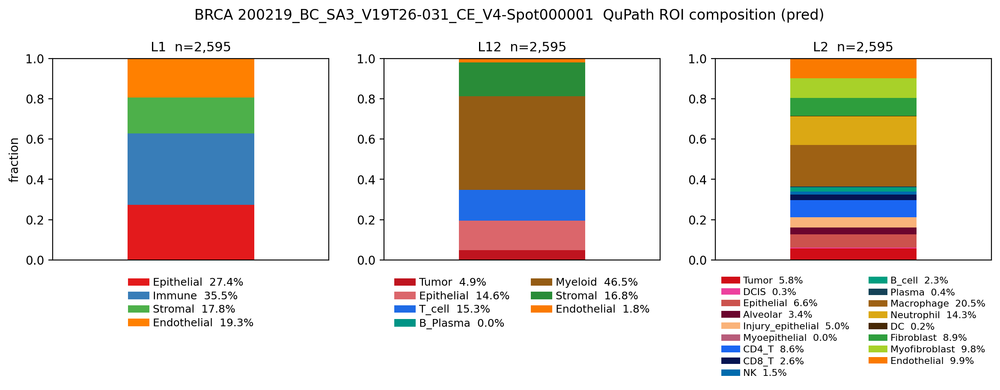

In [6]:
# ROI cell-type composition (100% stacked): L1 / L12 / L2
fig, comp_df = plot_roi_composition(
    SAMPLE_ROI,
    pred=pred,
    in_roi=in_roi,
    dpi=DPI,
    figsize=(12.0, 4.2),
    legend_fontsize_l1=9,
    legend_fontsize_l2=8,
    title_fontsize=11,
    save=SAVE_FIGURES,
    save_dpi=SAVE_DPI,
)
display(comp_df.pivot_table(index="class", columns="head", values="fraction").fillna(0).round(3))
display(fig)
plt.close(fig)


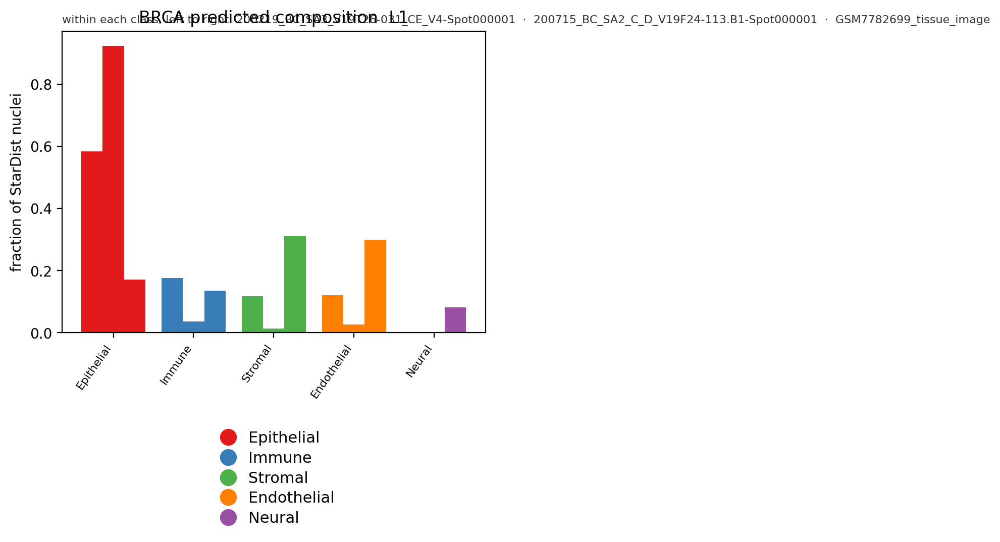

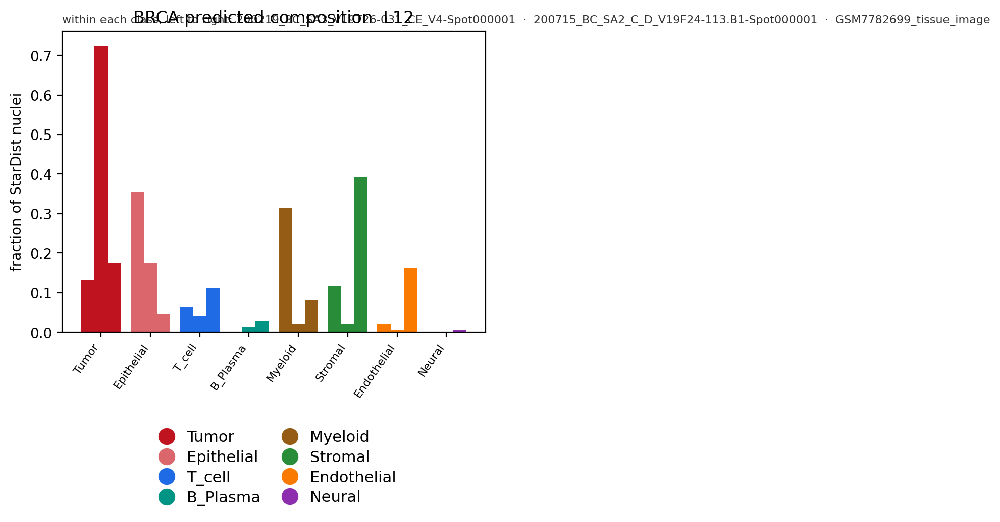

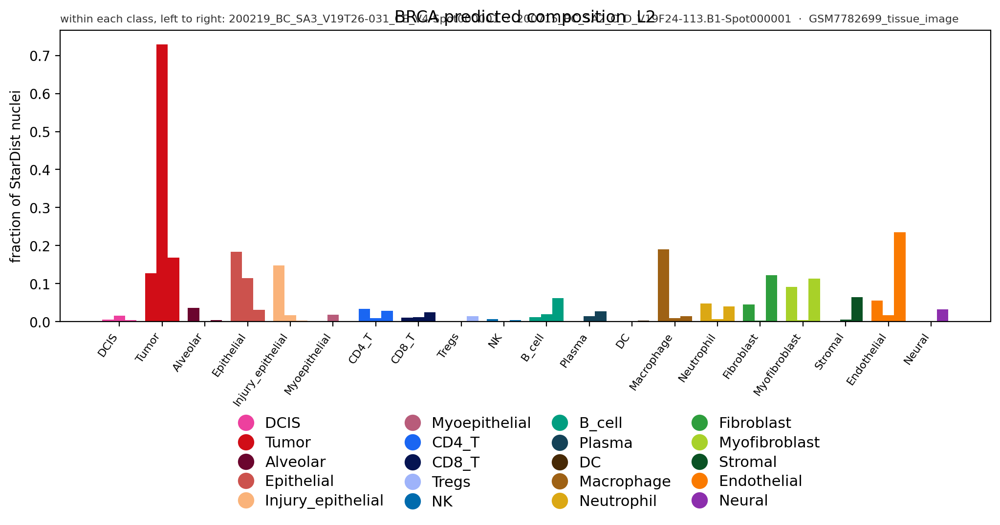

In [7]:
for fig in plot_composition(samples, save=SAVE_FIGURES, dpi=DPI, save_dpi=SAVE_DPI):
    display(fig)
    plt.close(fig)


## Histology-derived niche indices (TLS / SRI / TNI)

Same implementation as `code/Xenium_lung/histology_derived_niche_index.ipynb` §3, via `Hist2Pheno_pkg/histology_niche_index.py`. Lung ARI / FRI are not used: those members (AT1/AT2, activated fibrotic FBs, SPP1+ macrophages) are not pan-cancer L2 classes.

Scores use **L2 softmax**, not the argmax label. `ensure_l2_probs` caches `{sample}_l2_probs.npz` (first call reloads the cross-section checkpoint).

| Index | Abundance | Spatial (radius R) |
|--|--|--|
| **TLS** | sum(B_cell + Plasma + CD4_T + CD8_T + Tregs + DC) | `(B_local × T_local × DC_local)^(1/3)` |
| **SRI** | (Fibroblast + Myofibroblast + Stromal) / epithelium | Fib_local / Epi_local |
| **TNI** | (fibroblast + Macrophage + Endothelial) / epithelium | `(Fib × Mac × Endo)^(1/3) / Epi_local` |

Epithelium = Epithelial, Tumor, Alveolar, Injury_epithelial, DCIS, Myoepithelial. NK is left out of TLS, as in the lung T-cell set. `spatial_HE` is native HE pixels, so R = **55 µm** is converted with **each sample's** `geometry(sample)['mpp_um']` (GSM ~0.548; Zenodo JPEGs ~0.172), not 0.5. Hotspots are the within-slide 95th percentile. TLS, SRI, and TNI each use a 1×3 row: abundance, the spatial score without markers, then the same spatial map with cyan candidate nuclei. The two spatial panels share one color scale.


In [8]:
import importlib

for _p in (REPO / "code" / "Hist2Pheno_pkg", REPO / "code" / "Xenium_lung"):
    if str(_p) not in sys.path:
        sys.path.insert(0, str(_p))

import histology_niche_index as hni
importlib.reload(hni)
import histology_derived_niche_index as hdni
importlib.reload(hdni)
from histology_niche_index import OrganNicheConfig

import anndata as ad

TLS_RADIUS_UM = 55.0  # lung notebook cross-dataset TLS radius
RECOMPUTE_NICHE = True  # 2026.10.28, legacy niche cache lacks provenance; recompute from verified current probabilities

BRCA_NICHE = OrganNicheConfig(
    pan_organ="pancancer_brca",
    tls_b=("B_cell", "Plasma"),
    tls_t=("CD4_T", "CD8_T", "Tregs"),
    tls_dc=("DC",),
    epithelium=(
        "Epithelial", "Tumor", "Alveolar",
        "Injury_epithelial", "DCIS", "Myoepithelial",
    ),
    fibroblast=("Fibroblast", "Myofibroblast", "Stromal"),
    endothelial=("Endothelial",),
    macrophage=("Macrophage",),
    um_per_he_pixel=float(geometry(samples[0])["mpp_um"]),  # formula table only; cell below uses per-sample mpp
    spatial_radius_um=TLS_RADIUS_UM,
    cohort="BRCA",
)
print("µm/px by sample:", {s: round(float(geometry(s)["mpp_um"]), 4) for s in samples})
display(hni.index_formula_table(BRCA_NICHE))


µm/px by sample: {'200219_BC_SA3_V19T26-031_CE_V4-Spot000001': 0.1721, '200715_BC_SA2_C_D_V19F24-113.B1-Spot000001': 0.172, 'GSM7782699_tissue_image': 0.5476}


,index,formula
0,TLS,sum(B_cell+ Plasma+ CD4_T+ CD8_T+ Tregs+ DC)
1,TLS_spatial,(B_local × T_local × DC_local)^(1/3) within ra...
2,SRI_ratio,Fibroblast+Myofibroblast+Stromal / Epithelial+...
3,SRI_spatial,Fib_local / Epi_local within radius R μm
4,TNI_ratio,(Fibroblast+Myofibroblast+Stromal + Macrophage...
5,TNI_spatial,(Fib_local × myeloid_local × Endo_local)^(1/3)...


In [9]:
import numpy as np
niche_frames = {}
for sample in samples:
    paths = sample_paths(sample)
    niche_path = paths["pred"].with_name(f"{sample}_niche_indices.h5ad")
    mpp = float(geometry(sample)["mpp_um"])
    if niche_path.is_file() and not RECOMPUTE_NICHE:
        cached = ad.read_h5ad(niche_path)
        df = cached.obs.copy()
        xy = np.asarray(cached.obsm["spatial_HE"], dtype=np.float64)
        df["coord_x"] = xy[:, 0]
        df["coord_y"] = xy[:, 1]
        print(f"[niche] cache {niche_path.name}  n={len(df):,}  µm/px={mpp:.4f}")
    else:
        probs, class_names = ensure_l2_probs(sample)
        missing = hni.missing_index_cell_types(class_names, BRCA_NICHE)
        if missing:
            raise RuntimeError(f"{sample} missing niche compartments: {missing}")
        pred = ad.read_h5ad(paths["pred"])
        coords = np.asarray(pred.obsm["spatial_HE"], dtype=np.float64)
        df = pred.obs.copy()
        df["coord_x"] = coords[:, 0]
        df["coord_y"] = coords[:, 1]
        df = hni.add_abundance_indices(df, probs, class_names, BRCA_NICHE)
        df = hni.add_spatial_indices(
            df, probs, class_names, coords, BRCA_NICHE,
            radius_um=TLS_RADIUS_UM,
            um_per_pixel=mpp,
        )
        out = ad.AnnData(obs=df.drop(columns=["coord_x", "coord_y"]))
        out.obsm["spatial_HE"] = coords
        out.uns["tls_radius_um"] = TLS_RADIUS_UM
        out.uns["um_per_px"] = mpp
        __import__("pipeline_provenance").publish_derived_h5ad(out,niche_path,paths["pred"], probabilities=probs, class_names=class_names, obs_names=pred.obs_names, parameters={"config":BRCA_NICHE,"mpp":mpp,"radius_um":TLS_RADIUS_UM},algorithm=hni.__file__)
        print(f"[niche] wrote {niche_path}  n={len(df):,}")
    niche_frames[sample] = df
    print(f"  TLS hotspot: {hni.summarize_tls_hotspots(df)}")
    print(
        f"  mean TLS={df['idx_TLS'].mean():.3f}  TLS_spatial={df['idx_TLS_spatial'].mean():.3f}  "
        f"SRI={df['idx_SRI_ratio'].mean():.3f}  TNI={df['idx_TNI_ratio'].mean():.3f}"
    )

Loading best model for StarDist prediction...
  Checkpoint file: /home/lingyu/ssd2/Python/Hist2Pheno/data/PanCancer/result_uni2_A3_adjacent_spatial_k8mean_gate_paired_v2_seed42/cross_dataset_cv/A3_adjacent_spatial_k8mean_gate/best_mlp_gpu.pt
  Inferred hidden_dims from checkpoint: [768, 384, 192]
✓ StarDist model loaded
[niche] wrote /nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/BRCA/pred_uni2_A3_bestmlp_paired_v2_seed42/200219_BC_SA3_V19T26-031_CE_V4-Spot000001/200219_BC_SA3_V19T26-031_CE_V4-Spot000001_niche_indices.h5ad  n=391,069
  TLS hotspot: {'n_cells_total': 391069, 'n_candidate_cells': 19554, 'fraction_candidate': 0.05000140640142788, 'max_tls_spatial': 0.17379589935683717, 'mean_tls_spatial_candidate': 0.11284542412321158, 'centroid_x': 14164.049528797383, 'centroid_y': 34889.457493837595}
  mean TLS=0.142  TLS_spatial=0.040  SRI=2.633  TNI=6.156
[niche] wrote /nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/BRCA/pred_uni2_A3_bestmlp_paired_v2_seed42/200715_BC_SA2

/nobackup2/users/lingyu/Python/Hist2Pheno/data/Visium/BRCA/pred_uni2_A3_bestmlp_paired_v2_seed42/figures/tls_score_summary.csv


,sample,n,TLS_mean,TLS_median,TLS_p95,TLS_max,TLS_spatial_mean,TLS_spatial_median,TLS_spatial_p95,TLS_spatial_max,pearson,spearman,top5_jaccard,abundance_top5_also_spatial_top5,TLS_spatial_mean_in_abundance_top5,TLS_mean_in_spatial_top5
0,200219_BC_SA3_V19T26-031_CE_V4-Spot000001,391069,0.142,0.084,0.499,0.975,0.040,0.036,0.088,0.174,0.620,0.631,0.256,0.408,0.085,0.438
1,200715_BC_SA2_C_D_V19F24-113.B1-Spot000001,372413,0.138,0.087,0.455,0.991,0.033,0.028,0.069,0.227,0.546,0.448,0.258,0.410,0.068,0.397
2,GSM7782699_tissue_image,281049,0.237,0.164,0.737,0.994,0.056,0.050,0.112,0.222,0.629,0.589,0.254,0.405,0.101,0.623


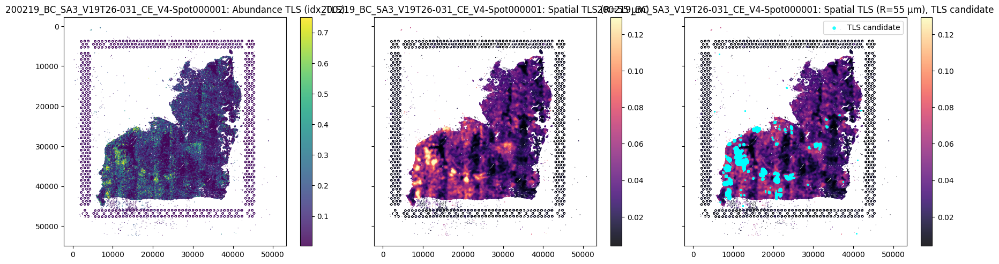

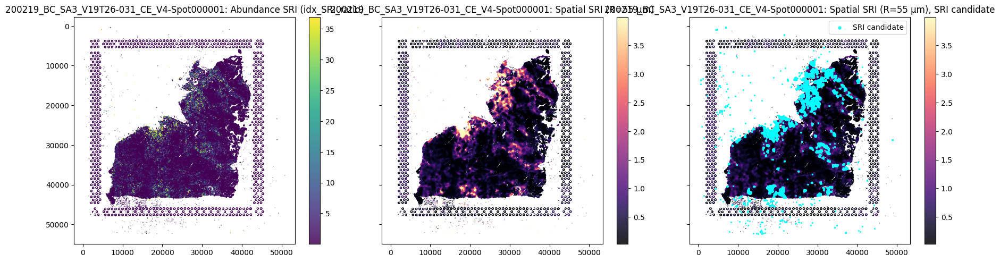

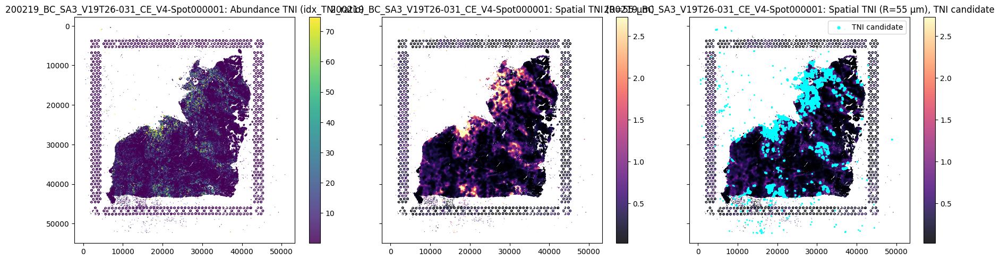

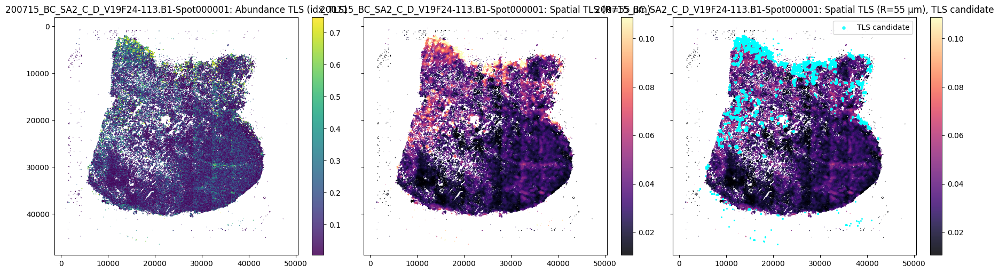

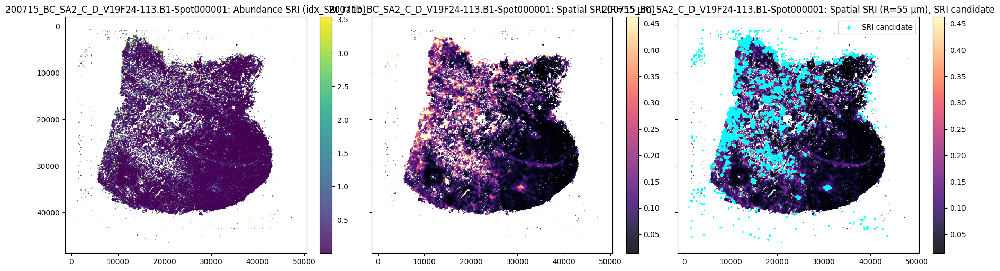

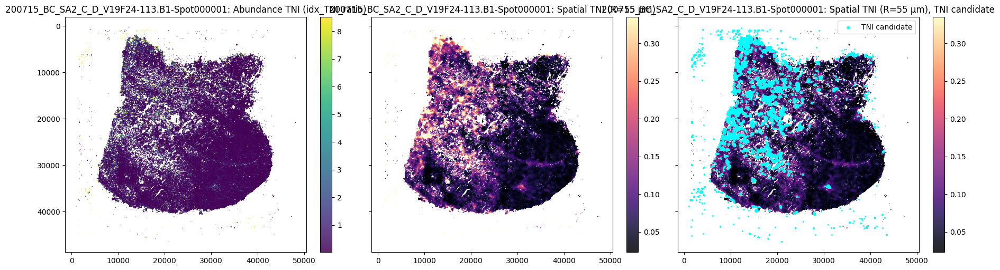

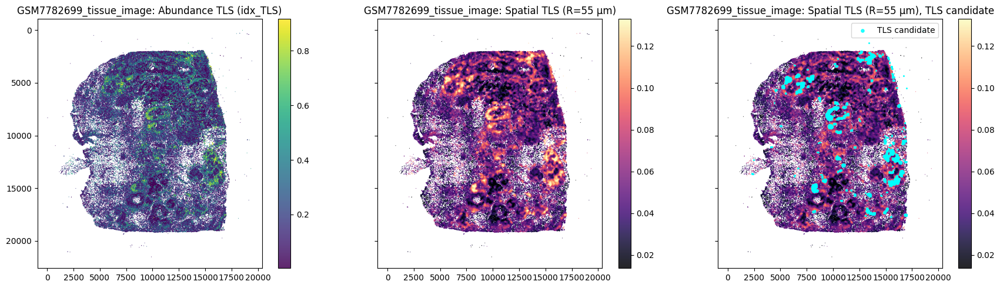

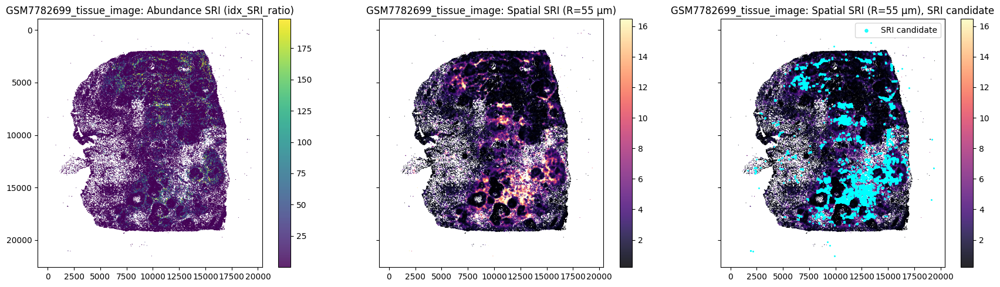

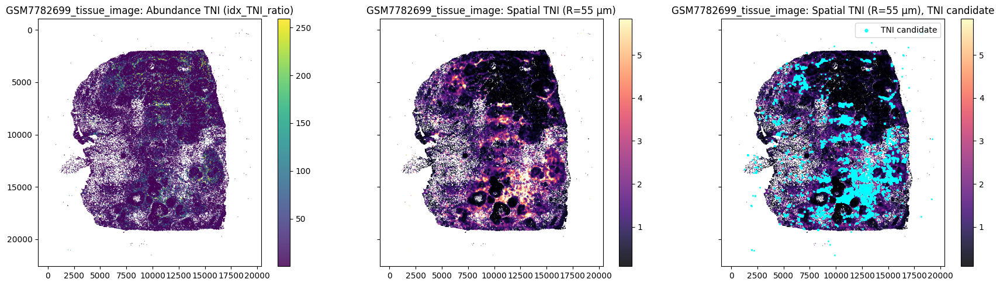

In [10]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

fig_dir = PRED_ROOT / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)


def tls_score_row(df, sample: str) -> dict:
    """Quantify abundance TLS vs spatial TLS on the same nuclei."""
    a = df["idx_TLS"].to_numpy(dtype=float)
    s = df["idx_TLS_spatial"].to_numpy(dtype=float)
    a_hi = a >= np.percentile(a, 95)
    s_hi = df["tls_candidate"].fillna(False).astype(bool).to_numpy()
    inter = int(np.logical_and(a_hi, s_hi).sum())
    union = int(np.logical_or(a_hi, s_hi).sum())
    n_a = int(a_hi.sum())
    return {
        "sample": sample,
        "n": int(len(df)),
        "TLS_mean": float(np.mean(a)),
        "TLS_median": float(np.median(a)),
        "TLS_p95": float(np.percentile(a, 95)),
        "TLS_max": float(np.max(a)),
        "TLS_spatial_mean": float(np.mean(s)),
        "TLS_spatial_median": float(np.median(s)),
        "TLS_spatial_p95": float(np.percentile(s, 95)),
        "TLS_spatial_max": float(np.max(s)),
        "pearson": float(np.corrcoef(a, s)[0, 1]),
        "spearman": float(pd.Series(a).corr(pd.Series(s), method="spearman")),
        "top5_jaccard": (inter / union) if union else float("nan"),
        "abundance_top5_also_spatial_top5": (inter / n_a) if n_a else float("nan"),
        "TLS_spatial_mean_in_abundance_top5": float(s[a_hi].mean()) if n_a else float("nan"),
        "TLS_mean_in_spatial_top5": float(a[s_hi].mean()) if s_hi.any() else float("nan"),
    }


quant_rows = [tls_score_row(df, sample) for sample, df in niche_frames.items()]
tls_quant = pd.DataFrame(quant_rows)
tls_quant_path = fig_dir / "tls_score_summary.csv"
tls_quant.to_csv(tls_quant_path, index=False)
print(tls_quant_path)
display(tls_quant.round(3))

for sample, df in niche_frames.items():
    fig, axes = hdni.plot_tls_abundance_vs_spatial(
        df,
        sample,
        radius_um=TLS_RADIUS_UM,
        use_entropy=False,
        split_spatial_candidates=True,
        dpi=DPI,
        save_dpi=SAVE_DPI,
        point_size=0.15,
        candidate_size=1.2,
        save_path=(fig_dir / f"{sample}_TLS_abundance_vs_spatial.png") if SAVE_FIGURES else None,
    )
    display(fig)
    plt.close(fig)

    for abundance_col, spatial_col, candidate_col, tag in (
        ("idx_SRI_ratio", "idx_SRI_spatial", "sri_candidate", "SRI"),
        ("idx_TNI_ratio", "idx_TNI_spatial", "tni_candidate", "TNI"),
    ):
        fig, axes = hdni.plot_tls_abundance_vs_spatial(
            df,
            sample,
            radius_um=TLS_RADIUS_UM,
            abundance_col=abundance_col,
            spatial_col=spatial_col,
            candidate_col=candidate_col,
            score_name=tag,
            use_entropy=False,
            split_spatial_candidates=True,
            dpi=DPI,
        save_dpi=SAVE_DPI,
        point_size=0.15,
            candidate_size=1.2,
            save_path=(fig_dir / f"{sample}_{tag}_abundance_vs_spatial.png") if SAVE_FIGURES else None,
        )
        display(fig)
        plt.close(fig)
